## 1. Import library 

In [1]:
#Tashfia Wahdah Fuady_202431013
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

### 2. Baca dataset, tampilkan head(), info(), dan describe()

In [2]:
#Tashfia Wahdah Fuady_202431013
data = pd.read_csv("BBCA.JK_10_years.csv")
data.head()

,Date,Adj Close,Close,High,Low,Open,Volume
0,2014-12-08 00:00:00+00:00,2246.477539,2655,2680,2645,2655,37435500
1,2014-12-09 00:00:00+00:00,2242.247314,2650,2680,2630,2660,38254000
2,2014-12-10 00:00:00+00:00,2250.708008,2660,2675,2630,2630,32998000
3,2014-12-11 00:00:00+00:00,2246.477539,2655,2675,2645,2660,54459500
4,2014-12-12 00:00:00+00:00,2242.247314,2650,2665,2640,2640,50302000


In [3]:
#Tashfia Wahdah Fuady_202431013
data.info()
data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 2473 entries, 0 to 2472
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2473 non-null   str    
 1   Adj Close  2473 non-null   float64
 2   Close      2473 non-null   int64  
 3   High       2473 non-null   int64  
 4   Low        2473 non-null   int64  
 5   Open       2473 non-null   int64  
 6   Volume     2473 non-null   int64  
dtypes: float64(1), int64(5), str(1)
memory usage: 195.7 KB


,Adj Close,Close,High,Low,Open,Volume
count,2473.000000,2473.000000,2473.000000,2473.000000,2473.000000,2.473000e+03
mean,5406.396759,5851.526486,5903.008492,5800.305297,5852.221998,8.119395e+07
std,2451.380659,2391.987223,2409.690125,2373.570507,2391.948707,5.535131e+07
min,1924.916504,2260.000000,2350.000000,2200.000000,2275.000000,0.000000e+00
25%,3143.089600,3600.000000,3630.000000,3575.000000,3620.000000,5.259010e+07
50%,5278.061035,5820.000000,5895.000000,5790.000000,5840.000000,7.076300e+07
75%,7262.393066,7750.000000,7850.000000,7700.000000,7750.000000,9.707940e+07
max,10895.657230,10950.000000,10950.000000,10775.000000,10900.000000,1.062862e+09


### 3. Bersihkan data

In [4]:
#Tashfia Wahdah Fuady_202431013
# Memeriksa nilai kosong sebelum pembersihan
print("Nilai kosong sebelum pembersihan:")
print(data.isna().sum())

# Menghapus kolom Date
df_clean = data.drop(columns=["Date"]).copy()

# Memeriksa nilai kosong setelah pembersihan
print("\nNilai kosong setelah pembersihan:")
print(df_clean.isna().sum())

Nilai kosong sebelum pembersihan:
Date         0
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

Nilai kosong setelah pembersihan:
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64


### 4. Pilih fitur klasteriasi

In [5]:
#Tashfia Wahdah Fuady_202431013
fitur = ["Close", "Volume"]
X = df_clean[fitur].copy()

print("Korelasi antar fitur:")
X.corr()

Korelasi antar fitur:


,Close,Volume
Close,1.000000,0.015744
Volume,0.015744,1.000000


### 5. Visualisasi sebaran data

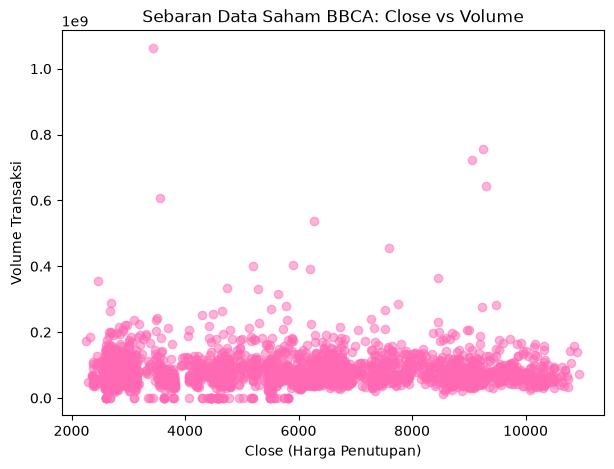

In [6]:
#Tashfia Wahdah Fuady_202431013
plt.figure(figsize=(7, 5))
plt.scatter(X["Close"], X["Volume"], alpha=0.5, color="#ff69b4")
plt.title("Sebaran Data Saham BBCA: Close vs Volume")
plt.xlabel("Close (Harga Penutupan)")
plt.ylabel("Volume Transaksi")
plt.show()

### 6. Standarisasi fitur dengan StandardScaler

In [7]:
#Tashfia Wahdah Fuady_202431013
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
df_scaled = pd.DataFrame(X_scaled, columns=fitur)

pd.DataFrame({
    "Mean": df_scaled.mean(),
    "Std": df_scaled.std(ddof=0)
})

,Mean,Std
Close,1.838849e-16,1.0
Volume,-1.149281e-16,1.0


### 7. Hitung inertia untuk k = 1 sampai 10

In [8]:
#Tashfia Wahdah Fuady_202431013
inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

pd.DataFrame({"k": range(1, 11), "Inertia": inertia})

,k,Inertia
0,1,4946.000000
1,2,3159.270757
2,3,2195.155137
3,4,1633.566322
4,5,1229.954505
5,6,1031.745517
6,7,851.106595
7,8,761.381720
8,9,673.985280
9,10,601.968934


### 8. Kurva Elbow

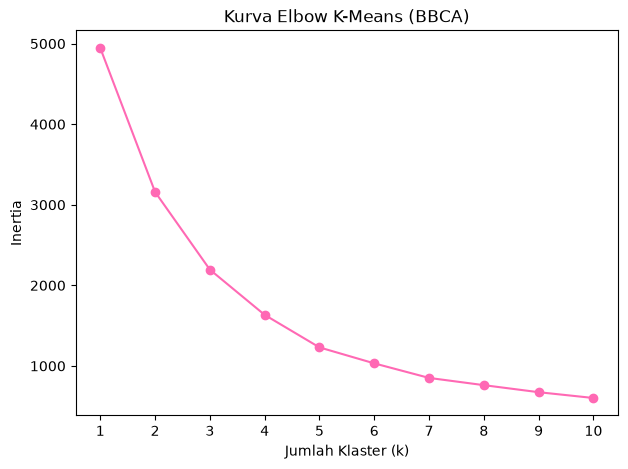

In [9]:
#Tashfia Wahdah Fuady_202431013
plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), inertia, marker="o", color="#ff69b4")
plt.title("Kurva Elbow K-Means (BBCA)")
plt.xlabel("Jumlah Klaster (k)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.show()

### 9. Silhouette Score dan DBI untuk k = 2 sampai 6

In [10]:
#Tashfia Wahdah Fuady_202431013
hasil = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=0)
    labels_k = km.fit_predict(X_scaled)
    hasil.append({
        "k": k,
        "Silhouette Score": silhouette_score(X_scaled, labels_k),
        "DBI": davies_bouldin_score(X_scaled, labels_k)
    })

pd.DataFrame(hasil)

,k,Silhouette Score,DBI
0,2,0.406015,0.992535
1,3,0.438807,0.810898
2,4,0.421210,0.793447
3,5,0.395327,0.751759
4,6,0.380065,0.812891


### 10. Latih model akhir dengan k terpilih (misal k = 4)

In [11]:
#Tashfia Wahdah Fuady_202431013
# Menentukan jumlah klaster
k_pilih = 4

# Melatih model K-Means
model_km = KMeans(
    n_clusters=k_pilih,
    n_init=10,
    random_state=0
)

klaster = model_km.fit_predict(X_scaled)

# Menampilkan posisi centroid
centers_df = pd.DataFrame(
    model_km.cluster_centers_,
    columns=fitur
)

centers_df.index.name = "Klaster"

print("Posisi Centroid:")
display(centers_df)

Posisi Centroid:


,Close,Volume
Klaster,,
0,-0.395355,1.351893
1,0.973675,-0.128482
2,-0.772621,-0.354680
3,0.374173,8.959641


In [12]:
#Tashfia Wahdah Fuady_202431013
# Menghitung jumlah anggota setiap klaster
jumlah_df = pd.Series(klaster).value_counts().sort_index().to_frame(
    "Jumlah Anggota"
)

jumlah_df.index.name = "Klaster"

print("Jumlah Anggota Setiap Klaster:")
display(jumlah_df)

Jumlah Anggota Setiap Klaster:


,Jumlah Anggota
Klaster,
0,319
1,1018
2,1125
3,11


### 11. Visualisasi hasil klasterisasi dan centroid

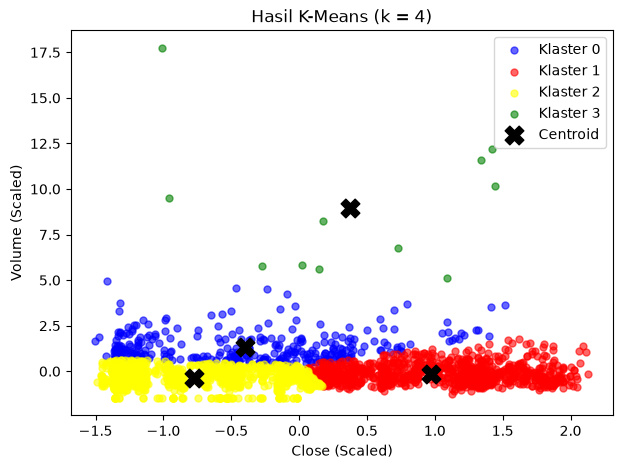

In [13]:
#Tashfia Wahdah Fuady_202431013
plt.figure(figsize=(7, 5))
warna = ["blue", "red", "yellow", "green"]
for i in range(k_pilih):
    plt.scatter(
        X_scaled[klaster == i, 0],
        X_scaled[klaster == i, 1],
        s=25,
        alpha=0.6,
        color=warna[i],
        label=f"Klaster {i}"
    )

plt.scatter(
    model_km.cluster_centers_[:, 0],
    model_km.cluster_centers_[:, 1],
    s=180,
    c="black",
    marker="X",
    label="Centroid"
)
plt.title(f"Hasil K-Means (k = {k_pilih})")
plt.xlabel("Close (Scaled)")
plt.ylabel("Volume (Scaled)")
plt.legend()
plt.show()

### 12. Profil klaster berdasarkan rata-rata nilai fitur asli

In [14]:
#Tashfia Wahdah Fuady_202431013
df_profil = X.copy()
df_profil["Klaster"] = klaster
profil = df_profil.groupby("Klaster").mean()

nama_klaster = {
    0: "Harga Menengah - Volume Rendah/Sedang",
    1: "Harga Tinggi - Volume Sedang",
    2: "Harga Rendah - Volume Sedang",
    3: "Lonjakan Volume Tinggi"
}
profil["Nama Klaster"] = profil.index.map(nama_klaster)
profil

,Close,Volume,Nama Klaster
Klaster,,,
0,4906.034483,1.560078e+08,Harga Menengah - Volume Rendah/Sedang
1,8180.073674,7.408374e+07,Harga Tinggi - Volume Sedang
2,4003.800000,6.156592e+07,Harga Rendah - Volume Sedang
3,6746.363636,5.770215e+08,Lonjakan Volume Tinggi


### 13. Evaluasi akhir

In [15]:
#Tashfia Wahdah Fuady_202431013
pd.DataFrame({
    "k": [k_pilih],
    "Silhouette Score": [silhouette_score(X_scaled, klaster)],
    "DBI": [davies_bouldin_score(X_scaled, klaster)]
})

,k,Silhouette Score,DBI
0,4,0.42121,0.793447
